In [1]:
from typing import Any
import pandas as pd
import numpy as np
from postgre_tools import Users, create_postgres_engine
import matplotlib.pyplot as plt


In [2]:
engine = create_postgres_engine(Users.AIRBNB.load_user())

# Set count to None if you want to fetch all rows
listings_row_count: int | None = None

if listings_row_count is not None and listings_row_count <= 0:
    raise ValueError("listings_row_count must be greater than 0")

listings_query = "SELECT id, price, room_type, accommodates, bedrooms, bathrooms, beds FROM listings"


if listings_row_count is not None:
    listings_query += f" LIMIT {listings_row_count}"


listings_df = pd.read_sql(listings_query, engine)

engine.dispose()

In [3]:
print(f"Columns in listings_df: {listings_df.columns}")
print(f"\nData types in listings_df:\n{listings_df.dtypes}")
listings_df

Columns in listings_df: Index(['id', 'price', 'room_type', 'accommodates', 'bedrooms', 'bathrooms',
       'beds'],
      dtype='str')

Data types in listings_df:
id                int64
price           float64
room_type           str
accommodates      int64
bedrooms        float64
bathrooms       float64
beds            float64
dtype: object


,id,price,room_type,accommodates,bedrooms,bathrooms,beds
0,145320,1503.50,Private room,2,1.0,1.0,1.0
1,164448,1030.00,Private room,2,NaN,1.0,2.0
2,220851,695.00,Private room,1,NaN,1.0,1.0
3,242188,972.00,Private room,1,NaN,1.0,1.0
4,273906,NaN,Entire home/apt,4,3.0,NaN,NaN
...,...,...,...,...,...,...,...
4801,1717861167246979973,NaN,Entire home/apt,2,1.0,1.0,1.0
4802,1718132464242032867,410.82,Private room,2,1.0,NaN,1.0
4803,1718263471917793029,456.47,Entire home/apt,2,1.0,0.5,1.0
4804,1718288866708700915,1266.50,Entire home/apt,2,1.0,NaN,1.0


In [4]:
features = ["room_type", "accommodates", "bedrooms", "bathrooms", "beds"]
clustering_features_df = listings_df[features]
clustering_features_df

,room_type,accommodates,bedrooms,bathrooms,beds
0,Private room,2,1.0,1.0,1.0
1,Private room,2,NaN,1.0,2.0
2,Private room,1,NaN,1.0,1.0
3,Private room,1,NaN,1.0,1.0
4,Entire home/apt,4,3.0,NaN,NaN
...,...,...,...,...,...
4801,Entire home/apt,2,1.0,1.0,1.0
4802,Private room,2,1.0,NaN,1.0
4803,Entire home/apt,2,1.0,0.5,1.0
4804,Entire home/apt,2,1.0,NaN,1.0


In [5]:
clustering_features_df.dtypes

room_type           str
accommodates      int64
bedrooms        float64
bathrooms       float64
beds            float64
dtype: object

In [6]:
# Check how many rows that does not have nan
clustering_features_df.dropna().shape[0]

2299

In [7]:
# Check how many values are missing for each column
clustering_features_df.isna().sum()

room_type          0
accommodates       0
bedrooms         697
bathrooms       2054
beds            1924
dtype: int64

In [8]:
# Check how many unique values there are in room_type column
unique_room_types = list(clustering_features_df["room_type"].unique())
unique_room_types

['Private room', 'Entire home/apt', 'Shared room', 'Hotel room']

In [9]:
# Count the number of listings for each room type
clustering_features_df["room_type"].value_counts()

room_type
Entire home/apt    3981
Private room        794
Shared room          28
Hotel room            3
Name: count, dtype: int64

In [ ]:
numerical_features = ["accommodates", "bedrooms", "bathrooms", "beds"]

# Do a statistical summary of the numerical features
clustering_features_df[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
accommodates,4806.0,3.602788,2.089303,1.0,2.0,3.0,5.0,16.0
bedrooms,4109.0,1.920662,1.227736,0.0,1.0,1.0,3.0,12.0
bathrooms,2752.0,1.321766,0.762232,0.5,1.0,1.0,1.5,12.0
beds,2882.0,2.364330,1.834288,1.0,1.0,2.0,3.0,22.0


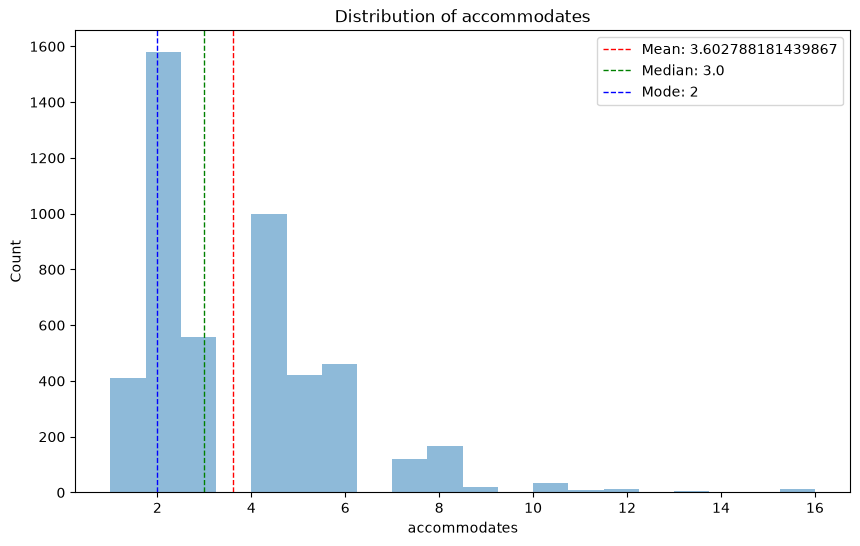

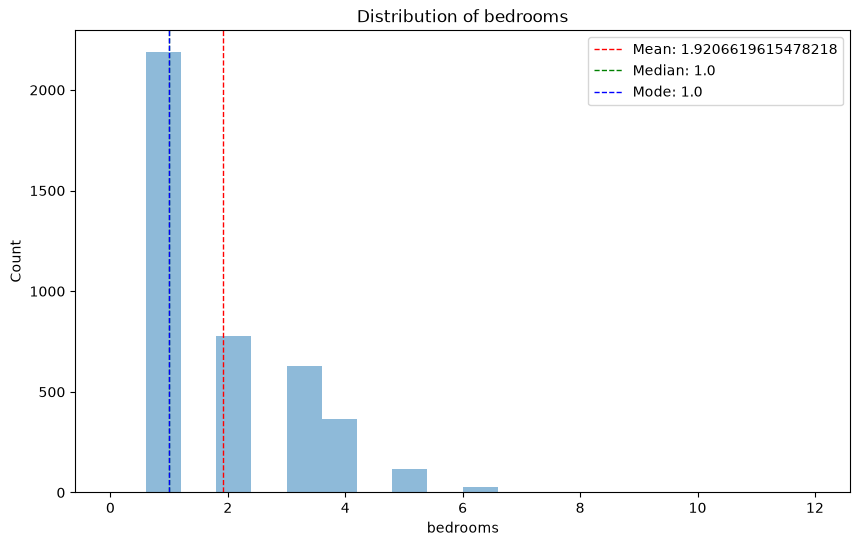

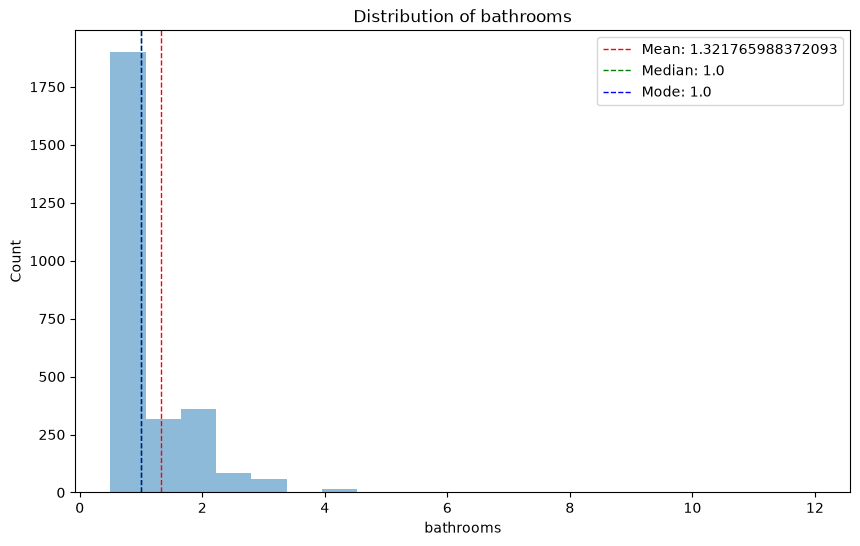

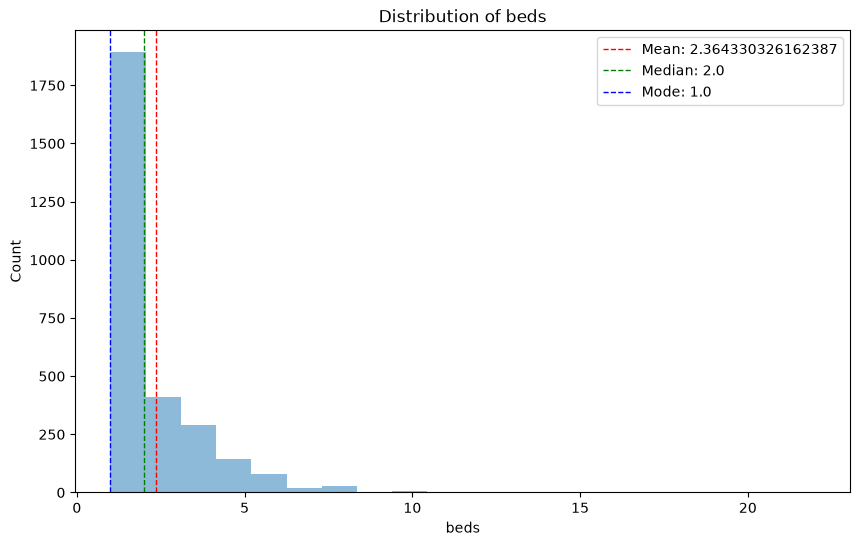

In [11]:
# print histograms for the numerical features. Include markers for mean, median, and mode
for feature in numerical_features:
    plt.figure(figsize=(10, 6))
    plt.hist(clustering_features_df[feature], bins=20, alpha=0.5)
    plt.xlabel(feature)
    plt.ylabel("Count")
    plt.title(f"Distribution of {feature}")
    mean_val = clustering_features_df[feature].mean()
    median_val = clustering_features_df[feature].median()
    mode_val = clustering_features_df[feature].mode()[0]
    plt.axvline(mean_val, color='r', linestyle='dashed', linewidth=1, label=f"Mean: {mean_val}")
    plt.axvline(median_val, color='g', linestyle='dashed', linewidth=1, label=f"Median: {median_val}")
    plt.axvline(mode_val, color='b', linestyle='dashed', linewidth=1, label=f"Mode: {mode_val}")
    plt.legend()
    plt.show()

ALl numerical features are mostly right skewed. If imputation global or grouped by imputation, then use median as it is more robust against outliers. 

# Imputation experiments

## Setup
Compare complete cases, global median, room-type median, and KNN imputation. All experiments use the previously defined `clustering_features_df` and `numerical_features`. The original data is never modified. KNN uses robust scaling (median/IQR) so that variables measured on different scales are comparable. The categorical `room_type` column is preserved, but is **not** used for KNN distances.

In [12]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import mean_absolute_error

missing_summary = pd.DataFrame({
    "missing_count": clustering_features_df.isna().sum(),
    "missing_percent": clustering_features_df.isna().mean().mul(100).round(2),
})
display(missing_summary)
print(f"Complete cases: {len(clustering_features_df.dropna()):,} / {len(clustering_features_df):,}")

,missing_count,missing_percent
room_type,0,0.00
accommodates,0,0.00
bedrooms,697,14.50
bathrooms,2054,42.74
beds,1924,40.03


Complete cases: 2,299 / 4,806


## Imputation methods
These functions fit their imputation statistics on the DataFrame supplied to them. They can therefore also be used with artificially masked data during evaluation. If a feature has no observed values anywhere, imputation fails explicitly instead of silently creating invalid clusters.

In [13]:
def _check_numeric_data(df: pd.DataFrame) -> None:
    empty_features = [col for col in numerical_features if df[col].notna().sum() == 0]
    if empty_features:
        raise ValueError(f"Cannot impute entirely missing numerical features: {empty_features}")


def impute_global_median(df: pd.DataFrame) -> pd.DataFrame:
    """Replace missing numeric values with each feature's global median."""
    _check_numeric_data(df)
    result = df.copy()
    result[numerical_features] = result[numerical_features].fillna(
        result[numerical_features].median()
    )
    return result


def impute_room_type_median(df: pd.DataFrame) -> pd.DataFrame:
    """Use medians within room_type, falling back to global medians."""
    _check_numeric_data(df)
    result = df.copy()
    group_medians = result.groupby("room_type")[numerical_features].transform("median")
    result[numerical_features] = (
        result[numerical_features]
        .fillna(group_medians)
        .fillna(result[numerical_features].median())
    )
    return result


def impute_knn(df: pd.DataFrame, n_neighbors: int = 5) -> pd.DataFrame:
    """KNN-impute numeric columns after robust scaling; preserve room_type."""
    _check_numeric_data(df)
    result = df.copy()
    numeric = result[numerical_features].astype(float)
    scaler = RobustScaler()
    scaled = scaler.fit_transform(numeric)
    imputed_scaled = KNNImputer(n_neighbors=n_neighbors).fit_transform(scaled)
    result[numerical_features] = scaler.inverse_transform(imputed_scaled)
    return result

## Baseline and complete imputed datasets
The complete-case baseline removes all rows with any missing feature. The imputed alternatives retain all rows. KNN can produce fractional bedroom/bed counts; these are left unrounded for evaluation. If integer counts are required in production, rounding is a separate modeling choice.

In [14]:
complete_cases_df = clustering_features_df.dropna().copy()

datasets = {
    "Complete cases": complete_cases_df,
    "Global median": impute_global_median(clustering_features_df),
    "Room-type median": impute_room_type_median(clustering_features_df),
    "KNN (k=5)": impute_knn(clustering_features_df, n_neighbors=5),
}

comparison = pd.DataFrame({
    "listings": {name: len(data) for name, data in datasets.items()},
    "missing_values_after": {name: int(data.isna().sum().sum()) for name, data in datasets.items()},
})
display(comparison)

# Example: datasets["Room-type median"]

,listings,missing_values_after
Complete cases,2299,0
Global median,4806,0
Room-type median,4806,0
KNN (k=5),4806,0


## Evaluate imputation with artificial missingness
For each repetition, randomly hide 20% of **observed** values in each numerical feature, impute from the remaining data, and compare against the original values using MAE. Values that were already missing are never treated as ground truth. Results are shown per feature, since bedroom counts and bathroom counts have different distributions. Note that simulated random missingness may not reproduce the real missingness mechanism.

In [15]:
def evaluate_imputation(
    df: pd.DataFrame,
    methods: dict,
    mask_fraction: float = 0.20,
    repeats: int = 5,
    seed: int = 42,
) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    records = []

    for repeat in range(repeats):
        masked_df = df.copy()
        masks = {}
        for feature in numerical_features:
            observed_indices = np.flatnonzero(df[feature].notna().to_numpy())
            n_mask = max(1, round(len(observed_indices) * mask_fraction))
            selected_positions = rng.choice(observed_indices, size=n_mask, replace=False)
            masks[feature] = selected_positions
            masked_df.iloc[selected_positions, masked_df.columns.get_loc(feature)] = np.nan

        for method_name, method in methods.items():
            imputed_df = method(masked_df)
            for feature in numerical_features:
                positions = masks[feature]
                truth = df[feature].iloc[positions].to_numpy(dtype=float)
                predicted = imputed_df[feature].iloc[positions].to_numpy(dtype=float)
                records.append({
                    "repeat": repeat + 1,
                    "method": method_name,
                    "feature": feature,
                    "mae": mean_absolute_error(truth, predicted),
                })

    return pd.DataFrame(records)


imputation_methods = {
    "Global median": impute_global_median,
    "Room-type median": impute_room_type_median,
    "KNN (k=5)": lambda df: impute_knn(df, n_neighbors=5),
}

imputation_errors = evaluate_imputation(
    clustering_features_df, imputation_methods, mask_fraction=0.20, repeats=5
)
mae_summary = imputation_errors.groupby(["method", "feature"])["mae"].agg(
    mean_mae="mean", std_mae="std"
).round(3)
display(mae_summary)

display(imputation_errors.pivot_table(
    index="method", columns="feature", values="mae", aggfunc="mean"
).round(3))

mean_mae  std_mae
method           feature                        
Global median    accommodates     1.605    0.023
                 bathrooms        0.339    0.052
                 bedrooms         0.935    0.032
                 beds             1.170    0.032
KNN (k=5)        accommodates     1.143    0.076
                 bathrooms        0.323    0.033
                 bedrooms         0.536    0.028
                 beds             0.823    0.044
Room-type median accommodates     1.397    0.041
                 bathrooms        0.339    0.052
                 bedrooms         0.935    0.032
                 beds             1.082    0.040

feature,accommodates,bathrooms,bedrooms,beds
method,,,,
Global median,1.605,0.339,0.935,1.170
KNN (k=5),1.143,0.323,0.536,0.823
Room-type median,1.397,0.339,0.935,1.082
